# How variable is the temperature? Daily, day-over-day and yearly swings in 40 cities, 1980-2025

**Questions**
1. How much does temperature swing *within a day* (diurnal range)?
2. How much does it jump *from one day to the next*?
3. How big is the *yearly* swing from coldest to hottest weeks?
4. Have these changed since 1980?

**Data:** [Open-Meteo Historical API](https://open-meteo.com/en/docs/historical-weather-api), ERA5 reanalysis (~25 km grid, hourly). Same model for every city, so comparisons are not distorted by different instruments or station gaps.

**This notebook so far:** 1) config, 2) cached fetch, 3) hourly to daily table, 4) sanity check, 5) metrics (simple version, no anomalies), 6) city summary table. Visuals, trends and validation come next.

## 1. Config

In [1]:
from pathlib import Path
import time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

START_YEAR, END_YEAR = 1980, 2025          # full years only
CHUNK_YEARS = 5                            # years per API request
HOURLY_VARS = ["temperature_2m", "apparent_temperature"]   # add "relative_humidity_2m" if you want it
API_URL = "https://archive-api.open-meteo.com/v1/archive"

DATA_DIR = Path("data")
RAW_DIR = DATA_DIR / "raw"
DAILY_DIR = DATA_DIR / "daily"
for d in (RAW_DIR, DAILY_DIR):
    d.mkdir(parents=True, exist_ok=True)

### City list
`tz` is the IANA timezone, used to convert UTC hours to *local* time (so "hour of day" is right and the daily max/min fall on the local calendar day).
`group` is a rough climate type, used later to colour and facet charts.

In [2]:
cities = [
    # name, lat, lon, tz, group
    ("Mumbai", 19.076, 72.878, "Asia/Kolkata", "Tropical"),
    ("Singapore", 1.352, 103.820, "Asia/Singapore", "Tropical"),
    ("Lagos", 6.524, 3.379, "Africa/Lagos", "Tropical"),
    ("Kinshasa", -4.442, 15.266, "Africa/Kinshasa", "Tropical"),
    ("Dhaka", 23.810, 90.412, "Asia/Dhaka", "Tropical"),
    ("Kolkata", 22.573, 88.364, "Asia/Kolkata", "Tropical"),
    ("Manila", 14.600, 120.984, "Asia/Manila", "Tropical"),
    ("Jakarta", -6.209, 106.846, "Asia/Jakarta", "Tropical"),
    ("Rio de Janeiro", -22.907, -43.173, "America/Sao_Paulo", "Tropical"),

    ("Nairobi", -1.286, 36.817, "Africa/Nairobi", "Highland"),
    ("Mexico City", 19.433, -99.133, "America/Mexico_City", "Highland"),
    ("Bangalore", 12.972, 77.594, "Asia/Kolkata", "Highland"),

    ("Dubai", 25.205, 55.271, "Asia/Dubai", "Arid"),
    ("Phoenix", 33.449, -112.074, "America/Phoenix", "Arid"),
    ("Cairo", 30.044, 31.236, "Africa/Cairo", "Arid"),
    ("Karachi", 24.861, 67.010, "Asia/Karachi", "Arid"),

    ("Delhi", 28.614, 77.209, "Asia/Kolkata", "Humid subtropical"),
    ("Tokyo", 35.690, 139.692, "Asia/Tokyo", "Humid subtropical"),
    ("Osaka", 34.694, 135.502, "Asia/Tokyo", "Humid subtropical"),
    ("Shanghai", 31.230, 121.474, "Asia/Shanghai", "Humid subtropical"),
    ("Guangzhou", 23.129, 113.264, "Asia/Shanghai", "Humid subtropical"),
    ("Chongqing", 29.563, 106.552, "Asia/Shanghai", "Humid subtropical"),
    ("Sao Paulo", -23.551, -46.633, "America/Sao_Paulo", "Humid subtropical"),
    ("Buenos Aires", -34.604, -58.382, "America/Argentina/Buenos_Aires", "Humid subtropical"),
    ("Sydney", -33.869, 151.209, "Australia/Sydney", "Humid subtropical"),
    ("Istanbul", 41.008, 28.978, "Europe/Istanbul", "Humid subtropical"),
    ("Dallas", 32.777, -96.797, "America/Chicago", "Humid subtropical"),

    ("Seattle", 47.606, -122.332, "America/Los_Angeles", "Maritime temperate"),
    ("London", 51.507, -0.128, "Europe/London", "Maritime temperate"),
    ("Los Angeles", 34.052, -118.244, "America/Los_Angeles", "Maritime temperate"),
    ("Cape Town", -33.925, 18.424, "Africa/Johannesburg", "Maritime temperate"),

    ("New York", 40.713, -74.006, "America/New_York", "Continental"),
    ("Toronto", 43.653, -79.383, "America/Toronto", "Continental"),
    ("Chicago", 41.878, -87.630, "America/Chicago", "Continental"),
    ("Minneapolis", 44.978, -93.265, "America/Chicago", "Continental"),
    ("Denver", 39.739, -104.990, "America/Denver", "Continental"),
    ("Moscow", 55.756, 37.617, "Europe/Moscow", "Continental"),
    ("Beijing", 39.904, 116.407, "Asia/Shanghai", "Continental"),
    ("Seoul", 37.567, 126.978, "Asia/Seoul", "Continental"),

    ("Reykjavik", 64.147, -21.942, "Atlantic/Reykjavik", "Subpolar"),
]
cities = pd.DataFrame(cities, columns=["city", "lat", "lon", "tz", "group"])
cities["slug"] = cities["city"].str.lower().str.replace(" ", "_")
print(len(cities), "cities")
cities.groupby("group")["city"].apply(", ".join)

40 cities


group
Arid                                     Dubai, Phoenix, Cairo, Karachi
Continental           New York, Toronto, Chicago, Minneapolis, Denve...
Highland                                Nairobi, Mexico City, Bangalore
Humid subtropical     Delhi, Tokyo, Osaka, Shanghai, Guangzhou, Chon...
Maritime temperate              Seattle, London, Los Angeles, Cape Town
Subpolar                                                      Reykjavik
Tropical              Mumbai, Singapore, Lagos, Kinshasa, Dhaka, Kol...
Name: city, dtype: str

## 2. Fetch (cached and resumable)

- One request per city per 5-year chunk, saved to `data/raw/<city>_<start>_<end>.parquet`. Existing files are skipped, so you can re-run the cell any time.
- Times are requested in **UTC** and converted to local time in step 3. That avoids duplicated or missing hours around daylight-saving changes.
- The free API has per-minute, per-hour and per-day limits, and bigger requests count for more. If the daily limit is hit, the loop stops cleanly. Just re-run the next day and it carries on where it left off. Check Open-Meteo's docs for current limits.
- `data/raw/_grid_info.csv` records the grid point and elevation ERA5 actually used for each city, which is worth a glance for coastal cities like Mumbai.

In [3]:
class DailyLimitReached(Exception):
    pass


def year_chunks(start_year, end_year, size):
    y = start_year
    while y <= end_year:
        yield y, min(y + size - 1, end_year)
        y += size


def fetch_chunk(row, y0, y1, max_retries=6):
    params = {
        "latitude": row.lat,
        "longitude": row.lon,
        "start_date": f"{y0}-01-01",
        "end_date": f"{y1}-12-31",
        "hourly": ",".join(HOURLY_VARS),
        "timezone": "GMT",
        "models": "era5",
    }
    for attempt in range(max_retries):
        r = requests.get(API_URL, params=params, timeout=120)
        if r.status_code == 200:
            return r.json()
        reason = ""
        try:
            reason = r.json().get("reason", "")
        except Exception:
            pass
        if r.status_code == 429:
            if "daily" in reason.lower():
                raise DailyLimitReached(reason)
            wait = 65 * (attempt + 1)          # minute/hour limit: wait and retry
            print(f"  rate limited ({reason or '429'}), sleeping {wait}s")
            time.sleep(wait)
            continue
        raise RuntimeError(f"HTTP {r.status_code}: {reason or r.text[:200]}")
    raise RuntimeError("too many retries")


def fetch_all(cities_df, pause=0.5):
    grid_rows = []
    for row in cities_df.itertuples():
        for y0, y1 in year_chunks(START_YEAR, END_YEAR, CHUNK_YEARS):
            path = RAW_DIR / f"{row.slug}_{y0}_{y1}.parquet"
            if path.exists():
                continue
            print(f"{row.city} {y0}-{y1}")
            j = fetch_chunk(row, y0, y1)
            df = pd.DataFrame(j["hourly"])
            df["time"] = pd.to_datetime(df["time"], utc=True)
            df.to_parquet(path, index=False)
            grid_rows.append({"city": row.city, "req_lat": row.lat, "req_lon": row.lon,
                              "grid_lat": j.get("latitude"), "grid_lon": j.get("longitude"),
                              "elevation_m": j.get("elevation")})
            time.sleep(pause)
    if grid_rows:
        info_path = RAW_DIR / "_grid_info.csv"
        new = pd.DataFrame(grid_rows).drop_duplicates("city")
        if info_path.exists():
            old = pd.read_csv(info_path)
            new = pd.concat([old, new]).drop_duplicates("city", keep="first")
        new.to_csv(info_path, index=False)


try:
    fetch_all(cities)
    print("Fetch complete.")
except DailyLimitReached as e:
    print("Daily API limit reached. Re-run this cell later to resume.\n", e)

Fetch complete.


## 3. Hourly to daily table (local time)

For each city: stitch chunks together, convert UTC to local time, then summarise each local calendar day.
Days with fewer than 23 hourly values (the first and last day can be partial after the timezone shift) are dropped.
DST days have 23 or 25 hours, which is why the threshold is 23 rather than 24.

In [4]:
def build_daily(row):
    files = sorted(RAW_DIR.glob(f"{row.slug}_*.parquet"))
    if not files:
        return None
    h = pd.concat([pd.read_parquet(f) for f in files]).drop_duplicates("time").sort_values("time")
    h["local"] = h["time"].dt.tz_convert(row.tz)
    h["date"] = h["local"].dt.tz_localize(None).dt.normalize()

    g = h.groupby("date")
    daily = pd.DataFrame({
        "n_hours": g["temperature_2m"].count(),
        "tmean": g["temperature_2m"].mean(),
        "tmax": g["temperature_2m"].max(),
        "tmin": g["temperature_2m"].min(),
        "tstd_hourly": g["temperature_2m"].std(),
    })
    if "apparent_temperature" in h:
        daily["app_mean"] = g["apparent_temperature"].mean()
        daily["app_max"] = g["apparent_temperature"].max()
        daily["app_min"] = g["apparent_temperature"].min()
    daily = daily[daily["n_hours"] >= 23].copy()
    daily["dtr"] = daily["tmax"] - daily["tmin"]          # diurnal temperature range
    daily.insert(0, "city", row.city)
    return daily.reset_index()


frames = [build_daily(r) for r in cities.itertuples()]
daily = pd.concat([f for f in frames if f is not None], ignore_index=True)
daily = daily.merge(cities[["city", "group"]], on="city")
daily["year"] = daily["date"].dt.year
daily["month"] = daily["date"].dt.month
daily.to_parquet(DAILY_DIR / "all_cities_daily.parquet", index=False)
print(daily.shape)
daily.head()

(672044, 14)


,date,city,n_hours,tmean,tmax,tmin,tstd_hourly,app_mean,app_max,app_min,dtr,group,year,month
0,1980-01-02,Mumbai,24,22.987500,25.9,19.7,1.884101,24.779167,28.1,20.1,6.2,Tropical,1980,1
1,1980-01-03,Mumbai,24,21.770833,26.3,17.8,3.030781,21.783333,26.7,18.2,8.5,Tropical,1980,1
2,1980-01-04,Mumbai,24,22.691667,28.6,17.5,3.837562,23.429167,31.0,17.3,11.1,Tropical,1980,1
3,1980-01-05,Mumbai,24,23.525000,28.4,18.7,3.313641,25.858333,30.5,20.5,9.7,Tropical,1980,1
4,1980-01-06,Mumbai,24,24.891667,29.9,19.7,3.641299,27.304167,32.9,21.9,10.2,Tropical,1980,1


## 4. Sanity check

Before computing anything fancy, check coverage and that the quick results match intuition
(Mumbai and Singapore low diurnal range; Phoenix, Denver and Dubai high; Seattle somewhere in between).

Cities with <99.9% coverage:
Empty DataFrame
Columns: [days, pct_complete]
Index: []


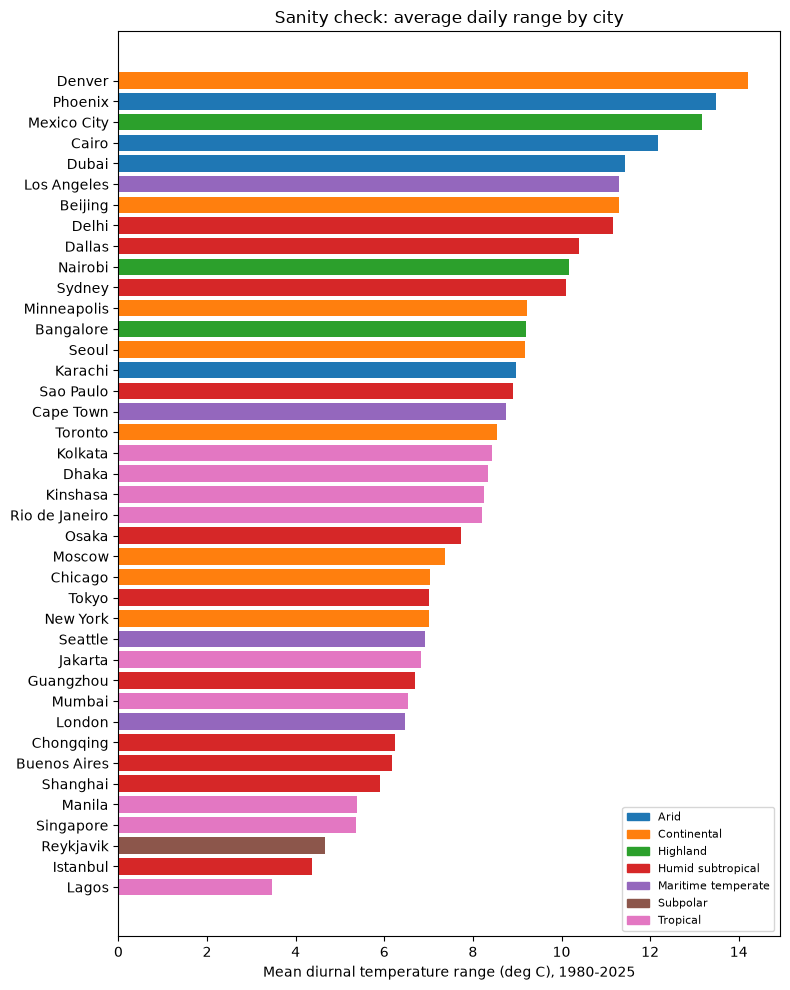

In [5]:
expected_days = (pd.Timestamp(f"{END_YEAR}-12-31") - pd.Timestamp(f"{START_YEAR}-01-01")).days + 1
cov = daily.groupby("city").size().rename("days").to_frame()
cov["pct_complete"] = (cov["days"] / expected_days * 100).round(2)
print("Cities with <99.9% coverage:")
print(cov[cov["pct_complete"] < 99.9])

mean_dtr = (daily.groupby(["group", "city"])["dtr"].mean()
            .reset_index().sort_values("dtr"))

fig, ax = plt.subplots(figsize=(8, 10))
palette = dict(zip(sorted(cities["group"].unique()), plt.cm.tab10.colors))
ax.barh(mean_dtr["city"], mean_dtr["dtr"], color=[palette[g] for g in mean_dtr["group"]])
ax.set_xlabel("Mean diurnal temperature range (deg C), 1980-2025")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()]
ax.legend(handles, palette.keys(), loc="lower right", fontsize=8)
ax.set_title("Sanity check: average daily range by city")
plt.tight_layout()
plt.show()

## 5. Metrics

Three scales, three metrics (plus "tail" variants):

| Scale | Primary | Variants |
|---|---|---|
| Within a day | Diurnal range = daily max - daily min | monthly profile |
| Day over day | Mean absolute change in the **daily high (tmax)** and the **daily low (tmin)**, abs(T(d) - T(d-1)) | 95th percentile of that change; days per year where the high or low changes by >=10 C within 2 days |
| Within a year | P95 - P5 of daily mean temp | std of daily means; extreme range (hottest hour - coldest hour); "feels-like" extreme range from apparent temperature |

**Why highs and lows, not the daily mean:** a warm afternoon and a cool night average out, so the daily mean hides the swings people actually feel ("30 C today, 15 C in two days" is about the high). Tracking tmax and tmin separately also shows whether a city's swings come from its days or its nights.

**A note on seasons:** the day-over-day numbers are raw changes, so they include a small amount of normal seasonal drift (spring warm-up, autumn cool-down). It adds a similar small amount to every city, so city-to-city comparisons and the big-swing counts are largely unaffected.

In [6]:
d = daily.sort_values(["city", "date"]).reset_index(drop=True)

SWING_VARS = ["tmax", "tmin"]   # swings are measured on daily highs and daily lows
SWING_C = 10                    # threshold (deg C) for a "big swing within 2 days"

# only compare days that are consecutive on the calendar
gap1 = d.groupby("city")["date"].diff().dt.days
gap2 = d.groupby("city")["date"].diff(2).dt.days

for v in SWING_VARS:
    gv = d.groupby("city")[v]
    d[f"{v}_d1"] = gv.diff().where(gap1 == 1)                    # today minus yesterday
    d[f"{v}_d2"] = (d[v] - gv.shift(2)).where(gap2 == 2)         # today minus 2 days ago
    d[f"abs_{v}_d1"] = d[f"{v}_d1"].abs()
    d[f"{v}_swing48"] = (d[f"{v}_d2"].abs() >= SWING_C).astype(int)

# a day counts as a big-swing day if either the high or the low moved >= SWING_C within 2 days
d["swing48_any"] = ((d["tmax_swing48"] + d["tmin_swing48"]) > 0).astype(int)
d[["city", "date", "tmax", "tmax_d1", "tmax_d2", "tmin", "tmin_d1", "tmin_d2"]].tail()

,city,date,tmax,tmax_d1,tmax_d2,tmin,tmin_d1,tmin_d2
672039,Toronto,2025-12-26,-3.0,-4.8,-6.8,-7.5,-0.5,-6.0
672040,Toronto,2025-12-27,-2.9,0.1,-4.7,-9.9,-2.4,-2.9
672041,Toronto,2025-12-28,0.7,3.6,3.7,-2.5,7.4,5.0
672042,Toronto,2025-12-29,8.6,7.9,11.5,-7.3,-4.8,2.6
672043,Toronto,2025-12-30,-4.1,-12.7,-4.8,-8.1,-0.8,-5.6


In [7]:
agg_spec = dict(
    dtr_mean=("dtr", "mean"),
    tmean_p05=("tmean", lambda s: s.quantile(0.05)),
    tmean_p95=("tmean", lambda s: s.quantile(0.95)),
    annual_std=("tmean", "std"),
    tmax_year=("tmax", "max"),
    tmin_year=("tmin", "min"),
    app_max_year=("app_max", "max"),
    app_min_year=("app_min", "min"),
)
for v in SWING_VARS:
    agg_spec[f"dod_abs_{v}"] = (f"abs_{v}_d1", "mean")                              # average day-to-day change
    agg_spec[f"dod_p95_{v}"] = (f"abs_{v}_d1", lambda s: s.quantile(0.95))          # 95th percentile (the big jumps)
    agg_spec[f"swing48_days_{v}"] = (f"{v}_swing48", "sum")                         # days with a >= SWING_C change in 2 days
agg_spec["swing48_days_any"] = ("swing48_any", "sum")

annual = d.groupby(["city", "year"]).agg(**agg_spec).reset_index()

annual["annual_p95_p5"] = annual["tmean_p95"] - annual["tmean_p05"]
annual["annual_extreme_range"] = annual["tmax_year"] - annual["tmin_year"]
annual["feels_like_extreme_range"] = annual["app_max_year"] - annual["app_min_year"]
annual = annual.merge(cities[["city", "group"]], on="city")

# monthly diurnal-range profile (city x month), for seasonal contrast later
dtr_month = d.groupby(["city", "month"])["dtr"].mean().unstack("month")

annual.to_parquet(DAILY_DIR / "annual_metrics.parquet", index=False)
d.to_parquet(DAILY_DIR / "daily_with_changes.parquet", index=False)
annual.head()

,city,year,dtr_mean,tmean_p05,tmean_p95,annual_std,tmax_year,tmin_year,app_max_year,app_min_year,...,dod_p95_tmax,swing48_days_tmax,dod_abs_tmin,dod_p95_tmin,swing48_days_tmin,swing48_days_any,annual_p95_p5,annual_extreme_range,feels_like_extreme_range,group
0,Bangalore,1980,9.757534,20.290000,26.805000,2.107378,36.4,12.0,39.3,10.9,...,2.50,0,0.735165,1.90,0,0,6.515000,24.4,28.4,Highland
1,Bangalore,1981,9.280548,19.040833,26.640833,2.166747,34.1,8.5,38.2,5.4,...,2.18,0,0.793699,2.20,0,0,7.600000,25.6,32.8,Highland
2,Bangalore,1982,9.536438,19.431667,26.788333,2.275129,33.9,12.6,36.4,11.7,...,2.18,0,0.705753,1.80,0,0,7.356667,21.3,24.7,Highland
3,Bangalore,1983,9.207123,19.601667,28.485833,2.718275,36.0,11.6,38.7,10.6,...,2.50,0,0.726849,2.08,0,0,8.884167,24.4,28.1,Highland
4,Bangalore,1984,9.106284,19.890625,26.973958,2.130877,34.7,12.0,38.6,10.7,...,2.60,0,0.667486,1.90,0,0,7.083333,22.7,27.9,Highland


## 6. City summary (1980-2025 averages)

One row per city. Quick check of your hypotheses: Mumbai should have a low diurnal range, Seattle a larger one,
Dallas/New York/Denver high day-over-day variability in daily highs (and lows) with many big-swing days, and Toronto/Moscow/Minneapolis a huge yearly range.
`swing48_days_*` counts days per year where the high (or low) differs from two days earlier by at least `SWING_C` degrees.
Overlapping windows mean one event can count on consecutive days.

In [8]:
metrics = ["dtr_mean",
           "dod_abs_tmax", "dod_abs_tmin",
           "dod_p95_tmax", "dod_p95_tmin",
           "swing48_days_tmax", "swing48_days_tmin", "swing48_days_any",
           "annual_p95_p5", "annual_extreme_range", "feels_like_extreme_range"]
summary = annual.groupby("city")[metrics].mean().round(1)
summary = summary.join(cities.set_index("city")["group"])

pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 250)
summary.sort_values("swing48_days_any", ascending=False)

,dtr_mean,dod_abs_tmax,dod_abs_tmin,dod_p95_tmax,dod_p95_tmin,swing48_days_tmax,swing48_days_tmin,swing48_days_any,annual_p95_p5,annual_extreme_range,feels_like_extreme_range,group
city,,,,,,,,,,,,
Denver,14.2,4.0,2.3,10.7,6.6,53.0,14.7,58.9,29.9,59.5,64.4,Continental
Minneapolis,9.2,3.3,3.0,8.6,8.1,31.7,26.6,47.3,38.0,63.3,72.8,Continental
Dallas,10.4,2.8,2.6,8.1,7.3,27.0,23.2,42.1,26.8,47.7,57.8,Humid subtropical
Toronto,8.5,3.1,2.9,8.5,7.7,26.8,21.2,39.3,31.6,55.9,65.3,Continental
Chicago,7.0,3.1,2.5,8.4,7.0,29.0,16.7,37.3,32.3,55.5,67.1,Continental
Moscow,7.4,2.4,2.4,6.5,6.6,12.8,15.4,23.5,33.1,58.4,65.2,Continental
New York,7.0,2.8,2.2,7.3,5.9,15.5,8.3,20.0,28.9,49.8,59.8,Continental
Sydney,10.1,2.8,1.9,8.2,4.8,18.9,0.7,19.4,14.5,39.3,44.3,Humid subtropical
Beijing,11.3,2.6,1.9,6.9,4.6,10.1,1.1,11.0,33.5,54.7,62.4,Continental


In [9]:
# rank (1 = most variable) for the cities named in the hypotheses
ranks = summary[metrics].rank(ascending=False).astype(int)
ranks.loc[["Mumbai", "Seattle", "Dallas", "New York", "Toronto"]]

,dtr_mean,dod_abs_tmax,dod_abs_tmin,dod_p95_tmax,dod_p95_tmin,swing48_days_tmax,swing48_days_tmin,swing48_days_any,annual_p95_p5,annual_extreme_range,feels_like_extreme_range
city,,,,,,,,,,,
Mumbai,31,39,36,39,35,36,33,36,34,35,34
Seattle,28,20,18,21,21,20,19,21,20,18,17
Dallas,9,6,3,6,3,4,2,3,9,9,9
New York,26,6,7,7,7,7,7,7,8,8,8
Toronto,18,3,2,3,2,5,3,4,5,4,3


In [10]:
thresholds = [5, 8, 10, 12, 15]   # deg C, edit freely


def big_swing_days_per_year(d, thr):
    # a day counts if the high OR the low differs from two days earlier by at least thr
    big = (d["tmax_d2"].abs() >= thr) | (d["tmin_d2"].abs() >= thr)
    per_year = big.groupby([d["city"], d["year"]]).sum()
    return per_year.groupby("city").mean()          # average days per year, per city


sens = pd.DataFrame({f">={t}C": big_swing_days_per_year(d, t) for t in thresholds}).round(1)

print("Cities with zero big-swing days per year:")
print((sens == 0).sum().to_string())
print()

sens = sens.join(cities.set_index("city")["group"])
sens.sort_values(f">={thresholds[len(thresholds) // 2]}C", ascending=False)

Cities with zero big-swing days per year:
>=5C      1
>=8C      6
>=10C     8
>=12C    12
>=15C    20



,>=5C,>=8C,>=10C,>=12C,>=15C,group
city,,,,,,
Denver,187.8,96.6,58.9,35.8,14.9,Continental
Minneapolis,186.3,84.2,47.3,25.9,10.0,Continental
Dallas,154.0,73.1,42.1,22.0,7.7,Humid subtropical
Toronto,173.7,74.3,39.3,20.0,6.2,Continental
Chicago,163.3,70.4,37.3,17.9,4.8,Continental
Moscow,133.4,48.3,23.5,12.2,4.8,Continental
New York,131.7,45.7,20.0,8.4,1.8,Continental
Sydney,122.1,40.8,19.4,9.3,2.9,Humid subtropical
Beijing,114.0,30.5,11.0,4.0,0.5,Continental


## Next
7. Visuals: temperature carpets, ECDFs of day-over-day change, variability fingerprint scatter, seasonal bands
8. Trends: Theil-Sen slope per city and metric, 1980s vs 2016-2025
9. Validation against NOAA/Meteostat stations for a few cities